loose previous index column and use built in:

In [ ]:
import pandas as pd
reviews_new_index=pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Warehousing\Python Practice\Pandas_Dataframes\wine-reviews.csv")
reviews_new_index.drop(columns=["Unnamed: 0"], inplace=True)
print(reviews_new_index.head())

promote existing column to index with pd.read_csv("path", index_col=[index]):

In [ ]:
reviews_promote_index=pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Warehousing\Python Practice\Pandas_Dataframes\wine-reviews.csv", index_col=0)
print(reviews_promote_index.head())

set index in separate step w/ df.set_index("column_name",inplace=True):

In [ ]:
reviews_next_index=pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Warehousing\Python Practice\Pandas_Dataframes\wine-reviews.csv")
reviews_next_index.set_index("Unnamed: 0", inplace=True)
print(reviews_next_index.head())

I now have 3 ways of creating indexes. what are the diferences between each?

Method  	What it does    	When to use it

<b>pd.read_csv(path, index_col=0)</b>	Uses the CSV’s first column as the index during loading.	When the CSV already contains the index you want.

<b>df.set_index("Unnamed: 0")</b>	Promotes an existing DataFrame column to the index, removing it from the regular columns.	When the data is already loaded.

<b>df.reset_index(drop=True)</b>	Replaces the current index with sequential numbers: 0, 1, 2, …. Discards the old index.

In [54]:
reviews=pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Warehousing\Python Practice\Pandas_Dataframes\wine-reviews.csv", index_col=0)
print(reviews.duplicated().sum())
reviews=reviews.drop_duplicates(ignore_index=True)
print(reviews.duplicated().sum())
print(reviews.head())

9983
0
    country                                        description  \
0     Italy  Aromas include tropical fruit, broom, brimston...   
1  Portugal  This is ripe and fruity, a wine that is smooth...   
2        US  Tart and snappy, the flavors of lime flesh and...   
3        US  Pineapple rind, lemon pith and orange blossom ...   
4        US  Much like the regular bottling from 2012, this...   

                          designation  points  price           province  \
0                        Vulkà Bianco      87    NaN  Sicily & Sardinia   
1                            Avidagos      87   15.0              Douro   
2                                 NaN      87   14.0             Oregon   
3                Reserve Late Harvest      87   13.0           Michigan   
4  Vintner's Reserve Wild Child Block      87   65.0             Oregon   

              region_1           region_2         taster_name  \
0                 Etna                NaN       Kerin O’Keefe   
1              

1. Filter French wines

In [ ]:
## one step
french= reviews.loc[reviews["country"]=="France"]
print(french)

In [ ]:
## two step
is_french = reviews["country"] == "France"
french = reviews.loc[is_french]
print(french)

2. Wines per taster

without reset_index -> series, so taster names are referenced by .index count by .values
with reset_index -> referencable by column names


In [75]:
print(reviews.iloc[:,[-1, -2]].head())
review_freq=reviews["taster_name"].value_counts().reset_index()
print(review_freq)

                winery         variety
0              Nicosia     White Blend
1  Quinta dos Avidagos  Portuguese Red
2            Rainstorm      Pinot Gris
3           St. Julian        Riesling
4         Sweet Cheeks      Pinot Noir
           taster_name  count
0           Roger Voss  23560
1    Michael Schachner  14046
2        Kerin O’Keefe   9697
3         Paul Gregutt   8868
4       Virginie Boone   8708
5        Matt Kettmann   5730
6       Joe Czerwinski   4766
7     Sean P. Sullivan   4461
8   Anna Lee C. Iijima   4017
9           Jim Gordon   3766
10    Anne Krebiehl MW   3290
11       Lauren Buzzeo   1700
12     Susan Kostrzewa   1023
13       Mike DeSimone    461
14        Jeff Jenssen    436
15  Alexander Peartree    383
16        Carrie Dykes    129
17         Fiona Adams     24
18   Christina Pickard      6


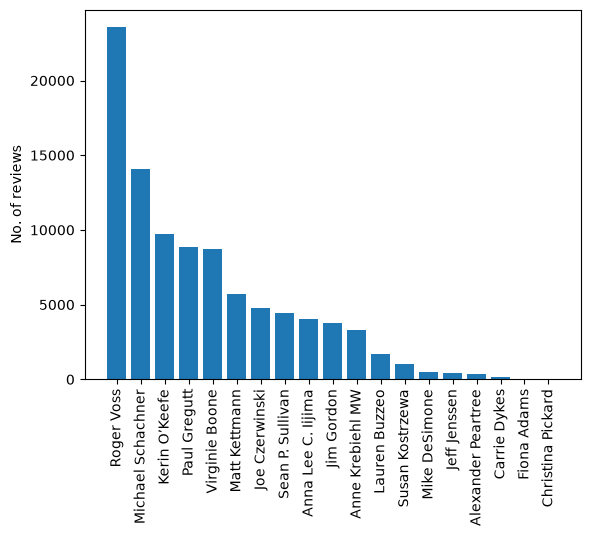

In [76]:
import matplotlib.pyplot as plt

plt.bar(review_freq["taster_name"],review_freq["count"])
plt.xticks(rotation=90)
plt.ylabel("No. of reviews")
plt.show()

4. Plot a histogram for the points. 

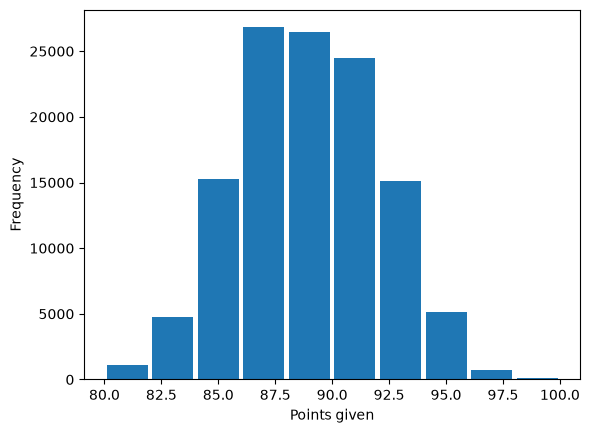

In [100]:
plt.hist(reviews["points"], rwidth=0.9)
plt.xlabel("Points given")
plt.ylabel("Frequency")
plt.show()

5. Show the first five rows for the columns “taster” and “points”. 
6. What is the highest price? 
7. What wine has the highest price?
8. What wines have a more than average rating (points) sorted in ascending order for price? 

In [144]:
first_five=reviews[["taster_name","points"]].head(5)
print(first_five)

print(str(reviews["price"].max())+" EUR")

print(reviews.loc[reviews["price"] == reviews["price"].max(), "title"])
print(reviews.loc[reviews["price"].idxmax(), "title"])
#reviews.loc[20]   # Wine B: index label 20
#reviews.iloc[1]   # Wine B: second row (position 1)

average_point=reviews["points"].mean()
higher_point_filter = reviews["points"]>average_point
higher_point=reviews.loc[higher_point_filter].sort_values("price", ascending=True)["title"]
print(higher_point)


          taster_name  points
0       Kerin O’Keefe      87
1          Roger Voss      87
2        Paul Gregutt      87
3  Alexander Peartree      87
4        Paul Gregutt      87
3300.0 EUR
76317    Château les Ormes Sorbet 2013  Médoc
Name: title, dtype: str
Château les Ormes Sorbet 2013  Médoc
41819      Borsao 2008 Monte Oton Garnacha (Campo de Borja)
61159     Hogue 2008 Red Table Wine Red (Columbia Valley...
33955     Herdade dos Machados 2012 Toutalga Red (Alente...
90295     Caves Velhas 2013 D. Fuas Reserva Red (Terras ...
106989                     Borsao 2008 Red (Campo de Borja)
                                ...                        
119843               Simone Scaletta 2007 Chirlet  (Barolo)
119884    Quinta da Pacheca 2013 Pacheca Superior Red (D...
119887                      Seacampo 2011 Reserva Red (Dão)
119911     Le Mandolare 2015 Corte Menini  (Soave Classico)
119981    Domaine Ehrhart 2013 Domaine Saint-Rémy Herren...
Name: title, Length: 56737, dtype: str
